# Project 3 starter: quantum neural network architectures

Setup and building blocks for [Project 3](../../content/outline/projects.md). The notebook is organised around the four core elements, in the same order as the main tasks. Code you need but that isn't the point of the project (loading data, applying a circuit to every patch of every image efficiently, a classical classifier, a hybrid training loop, noisy simulation) is provided. The parts marked `TODO` are for you to write. How far you take the investigation from here is up to you. Start by reading the quanvolutional neural network paper {cite}`Henderson2020`.

In [1]:
# ---- Your group's settings (you will be given these) ----
SETTINGS = dict(
    DATASET="mnist",       # "mnist" or "fashion"
    IMAGE_SIZE=14,         # images are reduced from 28x28 to this size
    PATCH=2,               # patch size: PATCH x PATCH pixels -> PATCH**2 qubits
    N_TRAIN=1000, N_TEST=500,
    SEED=1234,
)
DATASET, IMAGE_SIZE, PATCH, SEED = (SETTINGS[k] for k in ["DATASET", "IMAGE_SIZE", "PATCH", "SEED"])
N_TRAIN, N_TEST = SETTINGS["N_TRAIN"], SETTINGS["N_TEST"]

In [2]:
import contextlib, copy, io, json, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer.primitives import EstimatorV2 as AerEstimator
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit_ibm_runtime.fake_provider import FakeFez

rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
DATA_DIR = Path("../data") if Path("../data").exists() else Path("data")

## Loading the data

`load` returns a random (but reproducible) subset of images from all ten classes, reduced to `IMAGE_SIZE` $\times$ `IMAGE_SIZE` pixels with values in $[0,1]$, and their labels $0$–$9$.

In [3]:
def load(train, n):
    cls = torchvision.datasets.MNIST if DATASET == "mnist" else torchvision.datasets.FashionMNIST
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):   # hide download progress
        ds = cls(DATA_DIR, train=train, download=True)
    idx = rng.choice(len(ds), n, replace=False)
    x = torch.tensor(ds.data.numpy()[idx] / 255.0, dtype=torch.float32)[:, None]
    x = torch.nn.functional.interpolate(x, size=(IMAGE_SIZE, IMAGE_SIZE), mode="area")[:, 0].numpy()
    return x, ds.targets.numpy()[idx]

x_train, y_train = load(train=True, n=N_TRAIN)
x_test, y_test = load(train=False, n=N_TEST)

def extract_patches(x, p=PATCH):
    # Non-overlapping p x p patches, flattened: shape (images, rows, cols, p*p).
    N, H, W = x.shape
    return x.reshape(N, H // p, p, W // p, p).transpose(0, 1, 3, 2, 4).reshape(N, H // p, W // p, p * p)

patches_train, patches_test = extract_patches(x_train), extract_patches(x_test)
print("images:", x_train.shape, " patches:", patches_train.shape)

images: (1000, 14, 14)  patches: (1000, 7, 7, 4)


## 1. Circuit design

A **quantum filter** is a `Filter`: a circuit whose data parameters `x` receive the pixels of one patch, optional trainable weights `w`, and a list of observables, each giving one output **channel**. `apply_filter` evaluates the filter on every patch of every image (and, optionally, for several sets of weights) in a single batched Aer call. It returns feature maps of shape (images, channels, rows, columns), and counts the circuit evaluations.

The example filter encodes each pixel with $R_Y(\pi x)$, applies one trainable $R_Y$ per qubit, and measures $Z$ on each qubit. It has **no entanglement**, so each channel is just a classical function of one pixel. Designing genuinely quantum filters is your job.

feature maps (1000, 4, 7, 7): 73500 circuit evaluations in 7.6 s


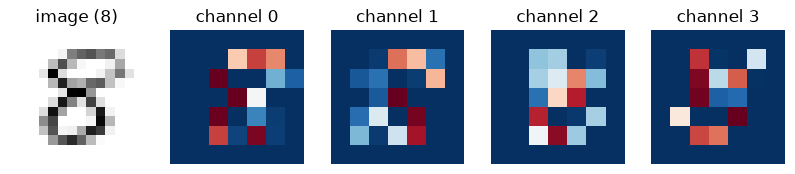

In [4]:
class Filter:
    def __init__(self, circuit, x_params, w_params, observables):
        self.qc, self.x, self.w, self.observables = circuit, list(x_params), list(w_params), observables

n_circuit_evaluations = 0
_estimators = {}                      # one Aer estimator per precision, reused (creating one is slow)

def apply_filter(filt, patches, w=None, shots=None):
    # Feature maps (images, channels, rows, cols). If w has shape (M, n_w), returns (M, images, channels, rows, cols).
    global n_circuit_evaluations
    N, h, wd, d = patches.shape
    X = patches.reshape(-1, d)
    bindings = {tuple(filt.x): X}
    many = w is not None and np.ndim(w) == 2
    if filt.w:
        W = np.atleast_2d(w)
        bindings = {tuple(filt.x): np.broadcast_to(X, (len(W),) + X.shape),
                    tuple(filt.w): np.broadcast_to(W[:, None, :], (len(W), len(X), W.shape[1]))}
    precision = 0.0 if shots is None else 1 / np.sqrt(shots)
    obs = [[[o]] for o in filt.observables] if filt.w else [[o] for o in filt.observables]   # broadcast over bindings
    if precision not in _estimators:
        _estimators[precision] = AerEstimator(options={"default_precision": precision})
    evs = _estimators[precision].run([(filt.qc, obs, bindings)]).result()[0].data.evs
    n_circuit_evaluations += int(np.prod(evs.shape[1:]))
    C = len(filt.observables)
    if filt.w:
        out = evs.reshape(C, -1, N, h, wd).transpose(1, 2, 0, 3, 4)       # (M, N, C, h, w)
        return out if many else out[0]
    return evs.reshape(C, N, h, wd).transpose(1, 0, 2, 3)

def example_filter(n_qubits=PATCH**2):
    x, w = ParameterVector("x", n_qubits), ParameterVector("w", n_qubits)
    qc = QuantumCircuit(n_qubits)
    for i in range(n_qubits):
        qc.ry(np.pi * x[i], i)
        qc.ry(w[i], i)
    observables = [SparsePauliOp.from_sparse_list([("Z", [i], 1.0)], n_qubits) for i in range(n_qubits)]
    return Filter(qc, x, w, observables)

filt = example_filter()
w0 = np.zeros(len(filt.w))
t = time.time()
features_train = apply_filter(filt, patches_train, w0)
features_test = apply_filter(filt, patches_test, w0)
print(f"feature maps {features_train.shape}: {n_circuit_evaluations} circuit evaluations in {time.time() - t:.1f} s")

fig, axes = plt.subplots(1, 1 + features_train.shape[1], figsize=(10, 2.2))
axes[0].imshow(x_train[0], cmap="Greys"); axes[0].set_title(f"image ({y_train[0]})")
for c, ax in enumerate(axes[1:]):
    ax.imshow(features_train[0, c], cmap="RdBu", vmin=-1, vmax=1); ax.set_title(f"channel {c}")
for ax in axes:
    ax.axis("off")
plt.show()

### A classical classifier

`Classifier` is a small classical network: by default a single linear layer, i.e. multinomial logistic regression, on the flattened features. `train_classifier` trains it on fixed features and returns the test accuracy with its binomial error. Use the **same** classifier for all your comparisons, including your classical baselines.

In [5]:
def Classifier(n_features, hidden=None):
    if hidden is None:
        return torch.nn.Sequential(torch.nn.Flatten(), torch.nn.Linear(n_features, 10))
    return torch.nn.Sequential(torch.nn.Flatten(), torch.nn.Linear(n_features, hidden), torch.nn.ReLU(),
                               torch.nn.Linear(hidden, 10))

def accuracy(model, f, y):
    with torch.no_grad():
        acc = (model(torch.tensor(f, dtype=torch.float32)).argmax(1).numpy() == y).mean()
    return acc, np.sqrt(acc * (1 - acc) / len(y))

def train_classifier(f_train, y_train, f_test, y_test, epochs=30, hidden=None, lr=1e-2):
    model = Classifier(int(np.prod(f_train.shape[1:])), hidden)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    Xtr, ytr = torch.tensor(f_train, dtype=torch.float32), torch.tensor(y_train)
    for _ in range(epochs):
        for idx in torch.randperm(len(Xtr)).split(50):
            opt.zero_grad()
            torch.nn.functional.cross_entropy(model(Xtr[idx]), ytr[idx]).backward()
            opt.step()
    return model, accuracy(model, f_test, y_test)

_, (acc, err) = train_classifier(features_train, y_train, features_test, y_test)
print(f"test accuracy with the example filter: {acc:.3f} ± {err:.3f}")

test accuracy with the example filter: 0.866 ± 0.015


## 2. Measurement and uncertainty

`apply_filter(..., shots=N)` adds the statistical noise of $N$ shots to every expectation value in the feature maps. Accuracies come with their binomial standard error. Repeat runs with different seeds for a fuller picture of the uncertainty.

## 3. Optimisation and gradients

### Gradient methods (to implement)

Implement the three gradient methods from [Lecture 5](../../content/lectures/lecture5.md). Each takes a function `f` and parameters `theta` (shape `(P,)`), and returns an estimate of $\nabla f$. `f` accepts a whole **batch** of parameter sets, with shape `(N, P)`, and returns `N` values. Evaluate everything you need in a single call to `f`, which is much faster.

`check_gradient` compares your implementation with a high-accuracy reference using exact (noiseless) values, and prints the relative error. Finite difference (with a small step) and parameter shift should agree to many digits. SPSA is random, so its check averages many estimates. The error of the average only falls as $1/\sqrt{n}$, so a relative error of order $10^{-1}$ to $10^{-2}$ is expected.

Here `f` is the classification loss on a batch of images, as a function of the **filter weights**, with the classical classifier held fixed. `filter_loss(filt, patches, y, model)` returns such a function. Finite differences and SPSA can be applied to it directly. The parameter-shift rule cannot. Why not? (Using the parameter shift via the chain rule is a possible further investigation.)

In [6]:
def finite_difference_gradient(f, theta, c=0.1):
    """Central finite-difference estimate of the gradient of f at theta."""
    raise NotImplementedError("TODO")

def spsa_gradient(f, theta, c=0.1, rng=rng):
    """SPSA estimate of the gradient of f at theta, using only two evaluations of f."""
    raise NotImplementedError("TODO")

def parameter_shift_gradient(f, theta):
    """Parameter-shift gradient of f at theta. Exact when f is an expectation value of a circuit
    whose parameters each appear once, in a Pauli rotation gate."""
    raise NotImplementedError("TODO")


def check_gradient(gradient_fn, f_exact, theta, n_average=1, **kwargs):
    """Compare gradient_fn(f_exact, theta) (averaged over n_average estimates) with a reference."""
    try:
        g = np.mean([gradient_fn(f_exact, theta, **kwargs) for _ in range(n_average)], axis=0)
    except NotImplementedError:
        print(f"{gradient_fn.__name__}: not implemented yet")
        return
    eps, P = 1e-5, len(theta)
    vals = f_exact(theta + np.vstack([eps * np.eye(P), -eps * np.eye(P)]))
    reference = (vals[:P] - vals[P:]) / (2 * eps)
    rel = np.max(np.abs(g - reference)) / np.max(np.abs(reference))
    print(f"{gradient_fn.__name__}: relative error = {rel:.1e}" + (f" (average of {n_average})" if n_average > 1 else ""))


def filter_loss(filt, patches, y, model, shots=None):
    """Return the function W_sets (M, n_w) -> cross-entropy loss on (patches, y) for each set of filter weights."""
    model64 = copy.deepcopy(model).double()           # double precision, so small finite-difference steps work
    def f(W_sets):
        feats = apply_filter(filt, patches, np.atleast_2d(W_sets), shots)      # (M, N, C, h, w)
        with torch.no_grad():
            logits = model64(torch.tensor(feats.reshape((-1,) + feats.shape[2:]), dtype=torch.float64))
            losses = torch.nn.functional.cross_entropy(logits, torch.tensor(np.tile(y, len(feats))), reduction="none")
        return losses.reshape(len(feats), -1).mean(1).numpy()
    return f

In [7]:
model = Classifier(int(np.prod(features_train.shape[1:])))
w_check = rng.uniform(0, 2 * np.pi, len(filt.w))
f_exact = filter_loss(filt, patches_train[:5], y_train[:5], model)

check_gradient(finite_difference_gradient, f_exact, w_check, c=1e-4)
check_gradient(spsa_gradient, f_exact, w_check, n_average=500, c=1e-4)

finite_difference_gradient: not implemented yet
spsa_gradient: not implemented yet


### Hybrid training

`train_hybrid` trains the classical classifier (with Adam, via PyTorch) and the quantum filter weights (with gradient descent, using any of your gradient functions) together. It records the test accuracy and the cost in circuit evaluations. For example:

```python
spsa = lambda f, w: spsa_gradient(f, w, c=0.1)
model, w, history = train_hybrid(filt, spsa, epochs=5)
```

In [8]:
def train_hybrid(filt, gradient_fn, epochs=5, batch_size=50, lr=1e-2, eta=0.1, w0=None, shots=None, seed=SEED):
    global n_circuit_evaluations
    torch.manual_seed(seed); r = np.random.default_rng(seed)
    w = r.uniform(0, 2 * np.pi, len(filt.w)) if w0 is None else np.array(w0, dtype=float)
    model = Classifier(len(filt.observables) * np.prod(patches_train.shape[1:3]))
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"test_acc": [], "test_acc_err": [], "cost": [], "w": []}
    cost0 = n_circuit_evaluations
    for epoch in range(epochs):
        for idx in np.array_split(r.permutation(N_TRAIN), N_TRAIN // batch_size):
            feats = torch.tensor(apply_filter(filt, patches_train[idx], w, shots), dtype=torch.float32)
            opt.zero_grad()                                                   # classical step
            torch.nn.functional.cross_entropy(model(feats), torch.tensor(y_train[idx])).backward()
            opt.step()
            w = w - eta * gradient_fn(filter_loss(filt, patches_train[idx], y_train[idx], model, shots), w)  # quantum step
        n_before = n_circuit_evaluations                                      # don't count monitoring as cost
        acc, err = accuracy(model, apply_filter(filt, patches_test, w), y_test)
        n_circuit_evaluations = n_before
        for k, v in [("test_acc", acc), ("test_acc_err", err), ("cost", n_circuit_evaluations - cost0), ("w", w.copy())]:
            history[k].append(v)
        print(f"epoch {epoch + 1}: test acc {acc:.3f} ± {err:.3f}  cost {n_circuit_evaluations - cost0}")
    return model, w, {k: np.array(v) for k, v in history.items()}

## 4. Noise

`noisy_feature_maps` computes feature maps on a (fake) backend with realistic noise. It measures all the filter's qubits and works for observables that are products of $Z$s. Simulating a noisy device is slow, so use it for a handful of images. To run on real hardware (bonus), pass a real backend.

In [9]:
def noisy_feature_maps(filt, patches, w, backend, shots=1000, seed=SEED):
    for o in filt.observables:
        if np.any(o.paulis.x):
            raise ValueError("noisy_feature_maps only supports products of Z: add basis changes for other observables")
    qc = filt.qc.copy(); qc.measure_all()
    tqc = generate_preset_pass_manager(backend=backend, optimization_level=3, seed_transpiler=seed).run(qc)
    N, h, wd, d = patches.shape
    X = patches.reshape(-1, d)
    values = {p: X[:, i] for i, p in enumerate(filt.x)} | {p: np.full(len(X), w[i]) for i, p in enumerate(filt.w)}
    sampler = Sampler(mode=backend)
    if backend.name.startswith("fake"):
        sampler.options.simulator.seed_simulator = seed
    res = sampler.run([(tqc, np.column_stack([values[p] for p in tqc.parameters]))], shots=shots).result()[0]
    out = np.zeros((len(filt.observables), len(X)))
    for j in range(len(X)):
        counts = res.data.meas.get_counts(loc=j)
        bits = np.array([[int(b) for b in s[::-1]] for s in counts]); n = np.array(list(counts.values()))
        for c, o in enumerate(filt.observables):
            out[c, j] = sum(coef.real * (n * (-1.0) ** bits[:, p.z].sum(1)).sum() / shots for coef, p in zip(o.coeffs, o.paulis))
    return out.reshape(-1, N, h, wd).transpose(1, 0, 2, 3)

noisy = noisy_feature_maps(filt, patches_test[:2], w0, FakeFez())
print("max |noisy - noiseless| in the feature maps:", np.abs(noisy - features_test[:2]).max().round(3))

max |noisy - noiseless| in the feature maps: 0.07


## Saving results

Save results as you go, so you never have to re-run long calculations just to change a plot.

In [10]:
def save_results(name, **arrays):
    """Save numpy arrays to results/<name>.npz, with the group settings in results/<name>.json."""
    out = Path("results"); out.mkdir(exist_ok=True)
    np.savez(out / f"{name}.npz", **arrays)
    (out / f"{name}.json").write_text(json.dumps({**SETTINGS, "time": time.ctime()}, indent=2, default=str))